# Week 7 -  NetCDF and `xarray`

In this lesson, we will get acquainted with a popuar format for working with multidimensional datasets called NetCDF and the Python package `xarray` which is based on NetCDF. 


In [1]:
# Import packages
import os              
import numpy as np
import pandas as pd

import xarray as xr   

### Variable values

The underlying data in the `xarray.DataArray` is a `numpy.array` that holds the variable values. 

In [2]:
# Values of a single variable at each point of the coords 
temp_data = np.array([np.zeros((5,5)), 
                      np.ones((5,5)), 
                      np.ones((5,5))*2]).astype(int)
temp_data

array([[[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]],

       [[1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1]],

       [[2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2]]])

### Dimensions and Coordinates

To specify the dimensions of our upcoming `xarray.DataArray`, we must examine how we've constructed the `numpy.array` holding the temperature data. 
The first dimension is time, the second is latitude, and longitude the third. 

From our exercises, we can also see that the coordinates (values of each dimension) are:

- time coordinates are 2022-09-01, 2022-09-02, 2022-09-03
- latitude coordinates are 70, 60, 50, 40, 30 (notice decreasing order)
- longitude coordinates are 60, 70, 80, 90, 100 (notice increasing order)

We add the dimensions as a tuple of strings and coordinates as a dictionary:

In [3]:
# Names of the dimensions in the required order
dims = ('time', 'lat', 'lon')

# Create coordinates to use for indexing along each dimension 
coords = {'time':pd.date_range("2022-09-01", "2022-09-03"),
          'lat':np.arange(70, 20, -10),
          'lon':np.arange(60, 110, 10)}  

#### Attributes

Next, we add the attributes (metadata) for our temperature data as a dictionary:

In [4]:
# Attributes (metadata) of the data array 
attrs = { 'long_name':'temperature across weather stations',
          'standard_name':'air_temperature',
          'units':'degree_c'}

#### Putting it all together

Finally, we put all these pieces together (data, dimensions, coordinates, and attributes) to create an `xarray.DataArray`:

In [5]:
# Initialize xarray.DataArray
temp = xr.DataArray(data = temp_data, 
                    dims = dims,
                    coords = coords,
                    attrs = attrs)
temp

<xarray.DataArray (time: 3, lat: 5, lon: 5)> Size: 600B
array([[[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]],

       [[1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1]],

       [[2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2]]])
Coordinates:
  * time     (time) datetime64[ns] 24B 2022-09-01 2022-09-02 2022-09-03
  * lat      (lat) int64 40B 70 60 50 40 30
  * lon      (lon) int64 40B 60 70 80 90 100
Attributes:
    long_name:      temperature across weather stations
    standard_name:  air_temperature
    units:          degree_c

We can also update the variable’s attributes after creating the object. 
Notice that each of the coordinates is also an `xarray.DataArray`, so we can add attributes to them.

In [6]:
# Update attributes
temp.attrs['description'] = 'Simple example of an xarray.DataArray'

# Add attributes to coordinates 
temp.time.attrs = {'description':'date of measurement'}

temp.lat.attrs['standard_name']= 'grid_latitude'
temp.lat.attrs['units'] = 'degree_N'

temp.lon.attrs['standard_name']= 'grid_longitude'
temp.lon.attrs['units'] = 'degree_E'
temp

<xarray.DataArray (time: 3, lat: 5, lon: 5)> Size: 600B
array([[[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]],

       [[1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1]],

       [[2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2],
        [2, 2, 2, 2, 2]]])
Coordinates:
  * time     (time) datetime64[ns] 24B 2022-09-01 2022-09-02 2022-09-03
  * lat      (lat) int64 40B 70 60 50 40 30
  * lon      (lon) int64 40B 60 70 80 90 100
Attributes:
    long_name:      temperature across weather stations
    standard_name:  air_temperature
    units:          degree_c
    description:    Simple example of an xarray.DataArray

In [8]:
# Access dimensions by name then use labels for indexing
temp.sel(time='2022-09-01', lat = 40, lon = 80)

<xarray.DataArray ()> Size: 8B
array(0)
Coordinates:
    time     datetime64[ns] 8B 2022-09-01
    lat      int64 8B 40
    lon      int64 8B 80
Attributes:
    long_name:      temperature across weather stations
    standard_name:  air_temperature
    units:          degree_c
    description:    Simple example of an xarray.DataArray

In [12]:
# Access dimensions by name, then use labels for indexing
temp.sel(time='2022-09-01', lat = 40, lon = 80).item()

0

In [11]:
temp.isel(time=0, lat=3, lon=2).item()

0

## Reduction

Average temperature at each station over time

In [13]:
avg_temp = temp.mean(dim = 'time')
avg_temp.attrs = {'long_name' : 'average tmeperature over three dats',
                  'standard_name' : 'air_temperature',
                  'units' : 'degree_C',
                  'cell_methods' : 'time:mean'
                  }

avg_temp

<xarray.DataArray (lat: 5, lon: 5)> Size: 200B
array([[1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])
Coordinates:
  * lat      (lat) int64 40B 70 60 50 40 30
  * lon      (lon) int64 40B 60 70 80 90 100
Attributes:
    long_name:      average tmeperature over three dats
    standard_name:  air_temperature
    units:          degree_C
    cell_methods:   time:mean

## `xarray.Dataset`

`xarray.Dataset` os like a netCDF file in memory: has multiple variables (each `xarray.DataArray`) dimensions, coordinates, attributes. 

In [14]:
# Make dictionaries w variables and attributes

data_vars = {'avg_temp' : avg_temp,
             'temp' : temp}

attrs = {'title':'Temperature data at weather stations: daily and average'}

# Create xarray.Dataset
temp_dataset = xr.Dataset(data_vars = data_vars,
                          attrs = attrs)

temp_dataset

<xarray.Dataset> Size: 904B
Dimensions:   (lat: 5, lon: 5, time: 3)
Coordinates:
  * lat       (lat) int64 40B 70 60 50 40 30
  * lon       (lon) int64 40B 60 70 80 90 100
  * time      (time) datetime64[ns] 24B 2022-09-01 2022-09-02 2022-09-03
Data variables:
    avg_temp  (lat, lon) float64 200B 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    temp      (time, lat, lon) int64 600B 0 0 0 0 0 0 0 0 0 ... 2 2 2 2 2 2 2 2
Attributes:
    title:    Temperature data at weather stations: daily and average

## Select variables

In [15]:
# Select one variable: returns an xarray.DataArray
temp_dataset['avg_temp']

<xarray.DataArray 'avg_temp' (lat: 5, lon: 5)> Size: 200B
array([[1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])
Coordinates:
  * lat      (lat) int64 40B 70 60 50 40 30
  * lon      (lon) int64 40B 60 70 80 90 100
Attributes:
    long_name:      average tmeperature over three dats
    standard_name:  air_temperature
    units:          degree_C
    cell_methods:   time:mean

In [16]:
# Select a list of variables
temp_dataset[['temp', 'avg_temp']]

<xarray.Dataset> Size: 904B
Dimensions:   (time: 3, lat: 5, lon: 5)
Coordinates:
  * lat       (lat) int64 40B 70 60 50 40 30
  * lon       (lon) int64 40B 60 70 80 90 100
  * time      (time) datetime64[ns] 24B 2022-09-01 2022-09-02 2022-09-03
Data variables:
    temp      (time, lat, lon) int64 600B 0 0 0 0 0 0 0 0 0 ... 2 2 2 2 2 2 2 2
    avg_temp  (lat, lon) float64 200B 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
Attributes:
    title:    Temperature data at weather stations: daily and average

In [17]:
# Open the 2025 data for buoy 46053 from the NDBC server
url = 'https://dods.ndbc.noaa.gov/thredds/dodsC/data/stdmet/46053/46053h2025.nc'
buoy = xr.open_dataset(url)
buoy

<xarray.Dataset> Size: 4MB
Dimensions:                  (time: 52550, latitude: 1, longitude: 1)
Coordinates:
  * time                     (time) datetime64[ns] 420kB 2025-01-01 ... 2025-...
  * latitude                 (latitude) float32 4B 34.24
  * longitude                (longitude) float32 4B -119.8
Data variables: (12/13)
    wind_dir                 (time, latitude, longitude) float64 420kB ...
    wind_spd                 (time, latitude, longitude) float32 210kB ...
    gust                     (time, latitude, longitude) float32 210kB ...
    wave_height              (time, latitude, longitude) float32 210kB ...
    dominant_wpd             (time, latitude, longitude) timedelta64[ns] 420kB ...
    average_wpd              (time, latitude, longitude) timedelta64[ns] 420kB ...
    ...                       ...
    air_pressure             (time, latitude, longitude) float32 210kB ...
    air_temperature          (time, latitude, longitude) float32 210kB ...
    sea_surface_temperature  (time, latitude, longitude) float32 210kB ...
    dewpt_temperature        (time, latitude, longitude) float32 210kB ...
    visibility               (time, latitude, longitude) float32 210kB ...
    water_level              (time, latitude, longitude) float32 210kB ...
Attributes:
    institution:                     NOAA National Data Buoy Center and Parti...
    url:                             http://dods.ndbc.noaa.gov
    quality:                         Automated QC checks with manual editing ...
    conventions:                     COARDS
    station:                         46053
    comment:                         EAST SANTA BARBARA  - 12NM Southwest of ...
    location:                        34.241 N 119.839 W 
    DODS_EXTRA.Unlimited_Dimension:  time

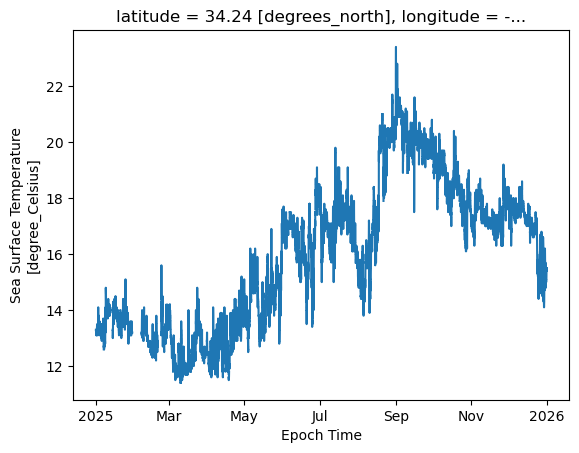

In [19]:
# Plot sea surface temperature time series
buoy['sea_surface_temperature'].isel(latitude=0, longitude=0).plot()